In [37]:
import pandas as pd
import numpy as np

In [38]:
df = pd.read_csv(r"C:\Users\dell\Downloads\IDS_resume.csv")

In [15]:
df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,count,srv_count,diff_srv_rate,same_srv_rate,dst_host_same_srv_rate,class
0,20,tcp,ftp,SF,233,774,1,1,0.00,1.00,0.22,normal
1,0,tcp,http,SF,312,2507,6,9,0.00,1.00,0.89,normal
2,0,tcp,http,REJ,0,0,1,1,0.00,1.00,1.00,normal
3,0,tcp,other,REJ,0,0,511,1,1.00,0.00,0.00,attack
4,0,tcp,daytime,RSTO,0,0,269,11,0.07,0.04,0.04,attack


In [16]:
print("dataset shape:", df.shape)

dataset shape: (45350, 12)


In [17]:
print("data types :",df.dtypes)

data types : duration                    int64
protocol_type              object
service                    object
flag                       object
src_bytes                   int64
dst_bytes                   int64
count                       int64
srv_count                   int64
diff_srv_rate             float64
same_srv_rate             float64
dst_host_same_srv_rate    float64
class                      object
dtype: object


In [18]:
print("\nmissing values :\n", df.isnull().sum())


missing values :
 duration                  0
protocol_type             0
service                   0
flag                      0
src_bytes                 0
dst_bytes                 0
count                     0
srv_count                 0
diff_srv_rate             0
same_srv_rate             0
dst_host_same_srv_rate    0
class                     0
dtype: int64


In [19]:
print(df.duplicated().sum())

7132


In [20]:
df2 = df.drop_duplicates()

In [21]:
df2["class"].value_counts()

class
normal    21401
attack    16817
Name: count, dtype: int64

In [22]:

df2.describe()

,duration,src_bytes,dst_bytes,count,srv_count,diff_srv_rate,same_srv_rate,dst_host_same_srv_rate
count,38218.000000,3.821800e+04,3.821800e+04,38218.000000,38218.000000,38218.000000,38218.000000,38218.000000
mean,353.915773,3.309658e+04,1.384837e+04,86.472369,26.352347,0.058125,0.633927,0.499840
std,2955.001131,3.723472e+06,2.049020e+06,107.033285,63.985958,0.160643,0.446148,0.445939
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,3.000000,2.000000,0.000000,0.080000,0.050000
50%,0.000000,4.600000e+01,1.700000e+01,20.000000,8.000000,0.000000,1.000000,0.380000
75%,0.000000,2.840000e+02,7.150000e+02,148.000000,18.000000,0.060000,1.000000,1.000000
max,42862.000000,6.933756e+08,4.002911e+08,511.000000,511.000000,1.000000,1.000000,1.000000


In [23]:
df2["protocol_type"].value_counts()


protocol_type
tcp     32446
udp      4763
icmp     1009
Name: count, dtype: int64

In [24]:

df2["service"].value_counts()


service
http         12533
private       6562
domain_u      3049
smtp          2478
ftp_data      2093
             ...  
pm_dump          2
tftp_u           1
http_2784        1
http_8001        1
harvest          1
Name: count, Length: 69, dtype: int64

In [25]:
df2["service"].value_counts().tail(15)

service
ntp_u         56
rje           30
pop_2         27
X11           27
shell         25
remote_job    24
printer       18
tim_i          4
urh_i          4
red_i          4
pm_dump        2
tftp_u         1
http_2784      1
http_8001      1
harvest        1
Name: count, dtype: int64

In [26]:

df2["flag"].value_counts()

flag
SF        22686
S0        11590
REJ        2581
RSTR        604
RSTO        505
S1          121
RSTOS0       38
S2           37
SH           25
S3           24
OTH           7
Name: count, dtype: int64

In [27]:
df2.groupby("class")["count"].mean()

class
attack    165.876494
normal     24.076258
Name: count, dtype: float64

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [29]:
X = df2.drop('class', axis=1)
y = df2['class']

# Identification des colonnes
cat_cols = ['protocol_type', 'service', 'flag']
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [30]:

X_encoded = pd.get_dummies(X, columns=cat_cols ,dtype=int)

In [31]:
X_encoded.head()

,duration,src_bytes,dst_bytes,count,srv_count,diff_srv_rate,same_srv_rate,dst_host_same_srv_rate,protocol_type_icmp,protocol_type_tcp,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,20,233,774,1,1,0.00,1.00,0.22,0,1,...,0,0,0,0,0,0,0,0,1,0
1,0,312,2507,6,9,0.00,1.00,0.89,0,1,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,1,0.00,1.00,1.00,0,1,...,1,0,0,0,0,0,0,0,0,0
3,0,0,0,511,1,1.00,0.00,0.00,0,1,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,269,11,0.07,0.04,0.04,0,1,...,0,1,0,0,0,0,0,0,0,0


In [32]:

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.4, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = RandomForestClassifier(n_estimators=250, random_state=42)
model.fit(X_train_scaled, y_train)


y_pred = model.predict(X_test_scaled)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[6710   36]
 [  12 8530]]
              precision    recall  f1-score   support

      attack       1.00      0.99      1.00      6746
      normal       1.00      1.00      1.00      8542

    accuracy                           1.00     15288
   macro avg       1.00      1.00      1.00     15288
weighted avg       1.00      1.00      1.00     15288



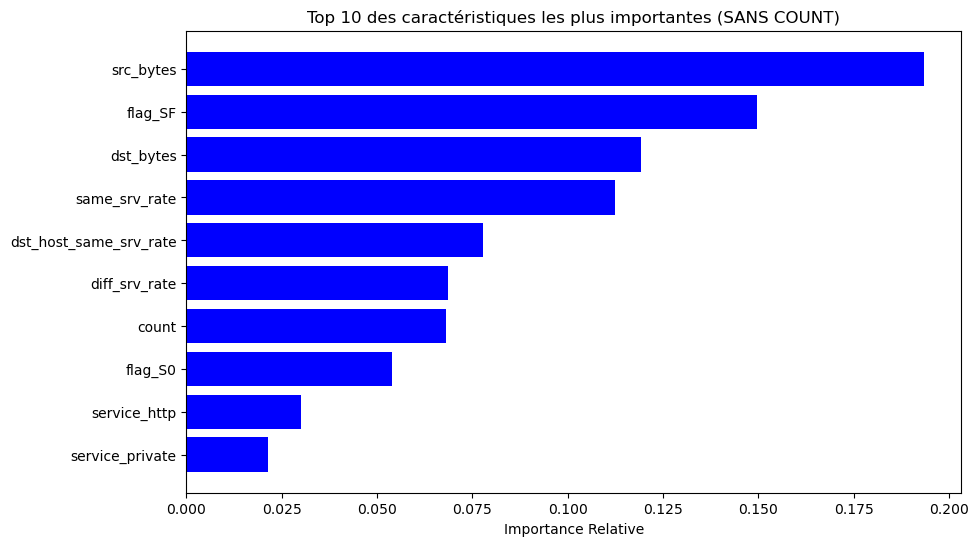

In [34]:
import matplotlib.pyplot as plt
import numpy as np


features = X_train_scaled2.columns if hasattr(X_train_scaled, 'columns') else X_encoded.columns
importances = model.feature_importances_
indices = np.argsort(importances)[-10:]  # On prend les 10 plus importantes

plt.figure(figsize=(10,6))
plt.title('Top 10 des caractéristiques les plus importantes (SANS COUNT)')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Importance Relative')
plt.show()

In [36]:
from sklearn.metrics import accuracy_score


acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc}")

Accuracy: 0.9968602825745683
